# 01 – Baseline analysis: 25-species, 3-resource cross-feeding community

No antibiotics. Susceptibility traits are loaded but **not used** by the dynamics.
Run `python generate_community.py` first (or let this notebook generate the default seed-42 community).

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from consumer_resource_model import (SimulationConfig, load_community_json, simulate, richness,
                                     shannon_diversity, uptake_rates, crossfeeding_potential,
                                     species_derivatives, resource_derivatives, save_community_json)
from generate_community import generate_community

SEED = 42
PATH = "community.json"
THRESH = 1e-6   # abundance below this counts as extinct

if os.path.exists(PATH):
    community = load_community_json(PATH)
else:
    community = generate_community(seed=SEED)
    save_community_json(community, PATH)
p = community.ecology
print(f"{p.n_species} species, {p.n_resources} resources, seed={community.seed}")

config = SimulationConfig(t_end=2000.0, n_points=2001)
res = simulate(community, config)
t, N, R = res.t, res.N, res.R
print("solver success:", res.success)

25 species, 3 resources, seed=42
solver success: True


In [2]:
START = 0.05   # same starting biomass for every species

community = load_community_json(PATH)          # or generate_community(seed=SEED)
community.ecology.initial_abundance[:] = START # overwrite all 25 values in memory
p = community.ecology

res = simulate(community, config)
t, N, R = res.t, res.N, res.R

## 1. Species abundances over time

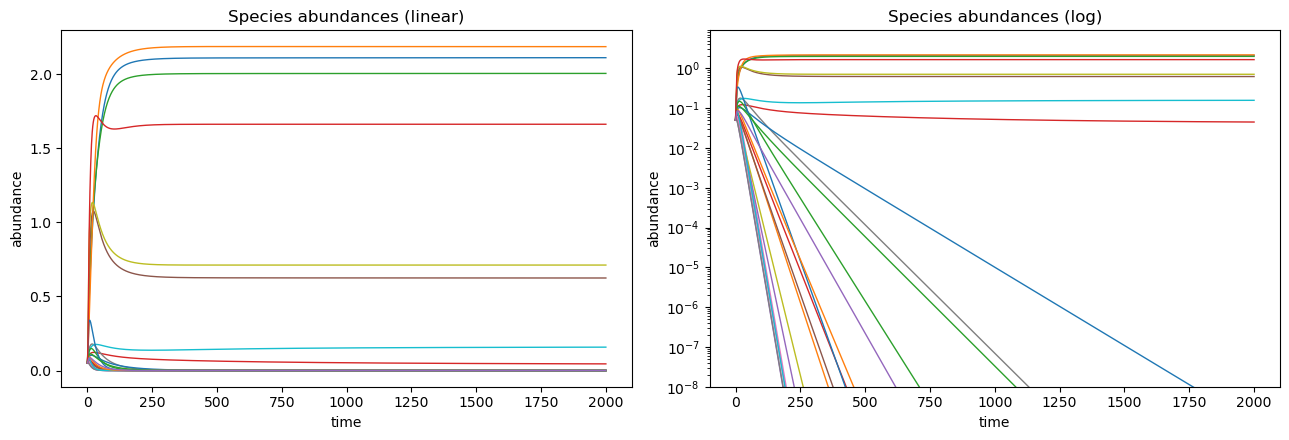

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for i in range(p.n_species):
    axes[0].plot(t, N[:, i], lw=1)
    axes[1].plot(t, np.maximum(N[:, i], 1e-12), lw=1)
axes[0].set(xlabel="time", ylabel="abundance", title="Species abundances (linear)")
axes[1].set(xlabel="time", ylabel="abundance", yscale="log", ylim=(1e-8, None), title="Species abundances (log)")
plt.tight_layout(); plt.show()

## 2. Resource concentrations over time

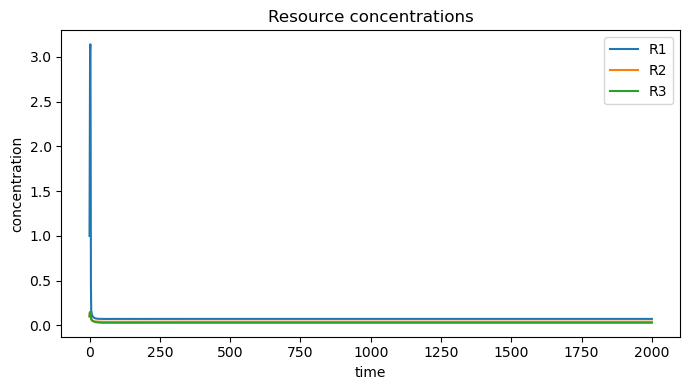

In [4]:
fig, ax = plt.subplots(figsize=(7, 4))
for j, name in enumerate(p.resource_names):
    ax.plot(t, R[:, j], label=name)
ax.set(xlabel="time", ylabel="concentration", title="Resource concentrations"); ax.legend()
plt.tight_layout(); plt.show()

## 3. Total biomass, richness and Shannon diversity

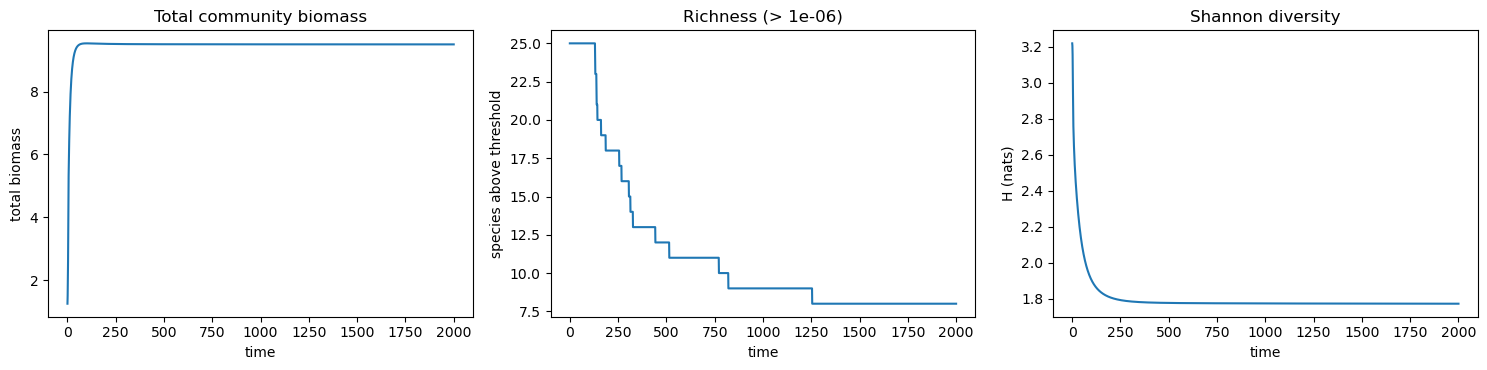

In [5]:
total = N.sum(axis=1)
rich = richness(N, THRESH)
H = shannon_diversity(N, THRESH)

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
axes[0].plot(t, total); axes[0].set(xlabel="time", ylabel="total biomass", title="Total community biomass")
axes[1].plot(t, rich); axes[1].set(xlabel="time", ylabel="species above threshold", title=f"Richness (> {THRESH:g})")
axes[2].plot(t, H); axes[2].set(xlabel="time", ylabel="H (nats)", title="Shannon diversity")
plt.tight_layout(); plt.show()

## 4. Species–resource consumption matrix and cross-feeding production matrix

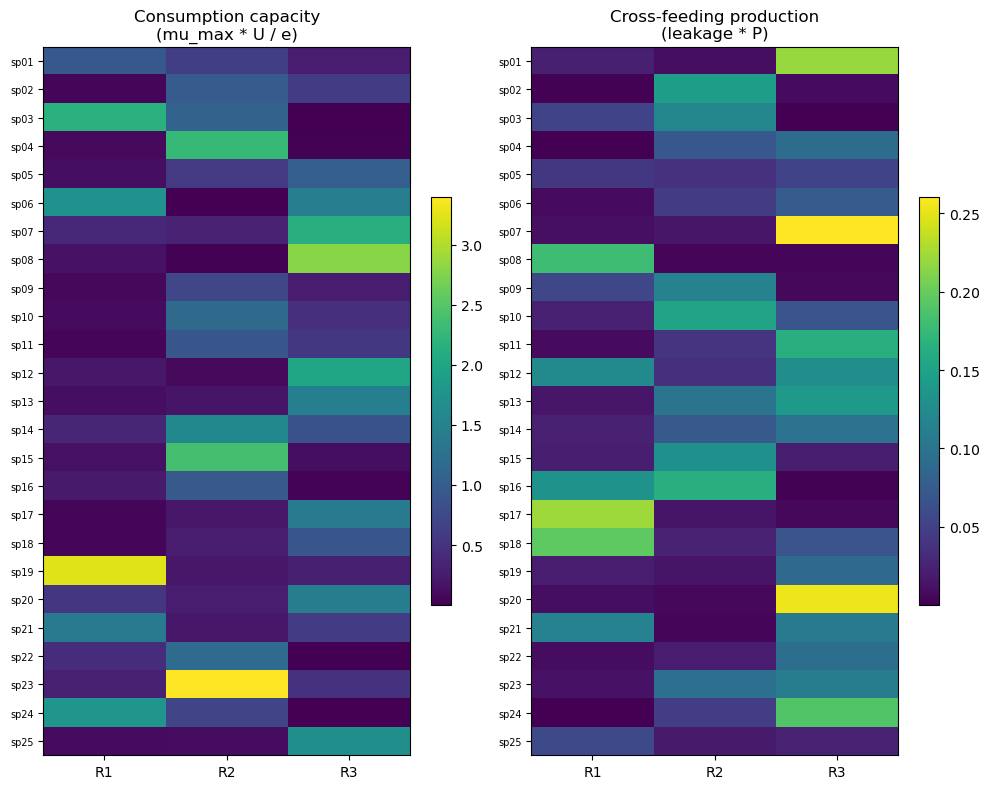

In [6]:
# Realised maximal consumption: preference-weighted uptake capacity per species/resource
vmax = p.mu_max[:, None] * p.preference / p.efficiency
# Cross-feeding production: leakage_i * P_ij = metabolite j released per unit resource taken up by species i
prod = p.leakage[:, None] * p.production

fig, axes = plt.subplots(1, 2, figsize=(10, 8))
for ax, mat, title in [(axes[0], vmax, "Consumption capacity\n(mu_max * U / e)"),
                       (axes[1], prod, "Cross-feeding production\n(leakage * P)")]:
    im = ax.imshow(mat, aspect="auto", cmap="viridis")
    ax.set_xticks(range(p.n_resources)); ax.set_xticklabels(p.resource_names)
    ax.set_yticks(range(p.n_species)); ax.set_yticklabels(p.species_names, fontsize=7)
    ax.set_title(title); plt.colorbar(im, ax=ax, fraction=0.05)
plt.tight_layout(); plt.show()

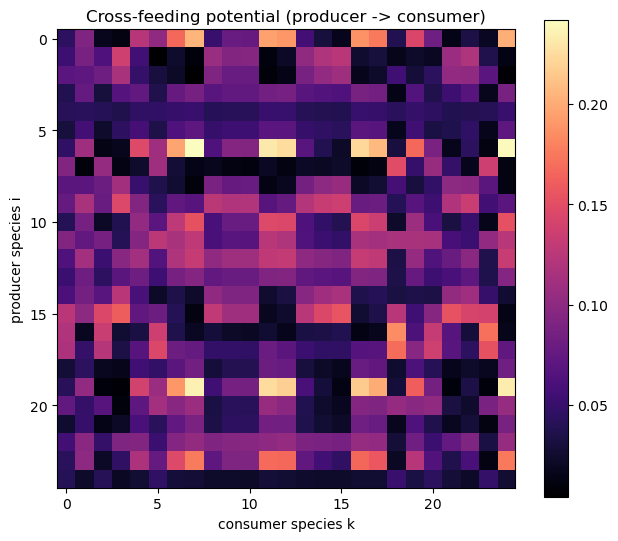

In [7]:
# Derived species-to-species cross-feeding potential (row i feeds column k)
A = crossfeeding_potential(p)
fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(A, cmap="magma")
ax.set_xlabel("consumer species k"); ax.set_ylabel("producer species i")
ax.set_title("Cross-feeding potential (producer -> consumer)"); plt.colorbar(im, ax=ax)
plt.tight_layout(); plt.show()

## 5. Extinctions and dominance

In [8]:
final = N[-1]
rows = []
for i, name in enumerate(p.species_names):
    below = np.where(N[:, i] <= THRESH)[0]
    rows.append({"species": name, "final_abundance": final[i], "final_fraction": final[i] / final.sum(),
                 "peak_abundance": N[:, i].max(),
                 "extinct": final[i] <= THRESH,
                 "mu_max": p.mu_max[i], "mortality": p.mortality[i],
                 "main_resource": p.resource_names[int(np.argmax(p.preference[i]))],
                 "susceptibility (unused)": community.future.susceptibility[i]})
summary = pd.DataFrame(rows).sort_values("final_abundance", ascending=False).reset_index(drop=True)
print(f"Survivors: {(~summary.extinct).sum()}  Extinct: {summary.extinct.sum()}")
display(summary.head(12))
dominant = summary[summary.final_fraction > 0.10].species.tolist()
print("Dominant species (>10% of final biomass):", dominant)
print("Extinct species:", summary[summary.extinct].species.tolist())

Survivors: 8  Extinct: 17


,species,final_abundance,final_fraction,peak_abundance,extinct,mu_max,mortality,main_resource,susceptibility (unused)
0,sp12,2.186178e+00,2.300110e-01,2.186924,False,0.956059,0.062992,R3,0.978767
1,sp01,2.111585e+00,2.221630e-01,2.111585,False,0.864374,0.069464,R1,0.477119
2,sp03,2.005473e+00,2.109988e-01,2.005473,False,0.915159,0.054380,R1,0.864696
3,sp24,1.662343e+00,1.748976e-01,1.720038,False,0.935873,0.118250,R1,0.499542
4,sp19,7.118950e-01,7.489953e-02,1.134431,False,0.896579,0.081237,R1,0.525821
5,sp06,6.245342e-01,6.570817e-02,1.075896,False,0.985373,0.124476,R1,0.284406
6,sp10,1.577557e-01,1.659771e-02,0.176185,False,0.670232,0.096956,R2,0.717060
7,sp04,4.490187e-02,4.724192e-03,0.122488,False,0.818421,0.065429,R2,0.285184
8,sp11,1.178097e-09,1.239493e-10,0.103129,True,0.622479,0.068947,R2,0.480394
9,sp08,2.463377e-14,2.591756e-15,0.179048,True,0.871639,0.082583,R3,0.462499


Dominant species (>10% of final biomass): ['sp12', 'sp01', 'sp03', 'sp24']
Extinct species: ['sp11', 'sp08', 'sp23', 'sp13', 'sp22', 'sp14', 'sp21', 'sp16', 'sp02', 'sp15', 'sp09', 'sp05', 'sp18', 'sp17', 'sp20', 'sp07', 'sp25']


## 6. Sanity checks: nonnegativity and approach to a stable endpoint

min abundance over run : -4.724e-24
min resource over run  : 2.852e-02
nonnegative (tol 1e-8) : True
max |dN/dt| at end: 3.46e-06   max |dR/dt| at end: 1.72e-08
max abundance change over last 10% of run: 7.91e-04


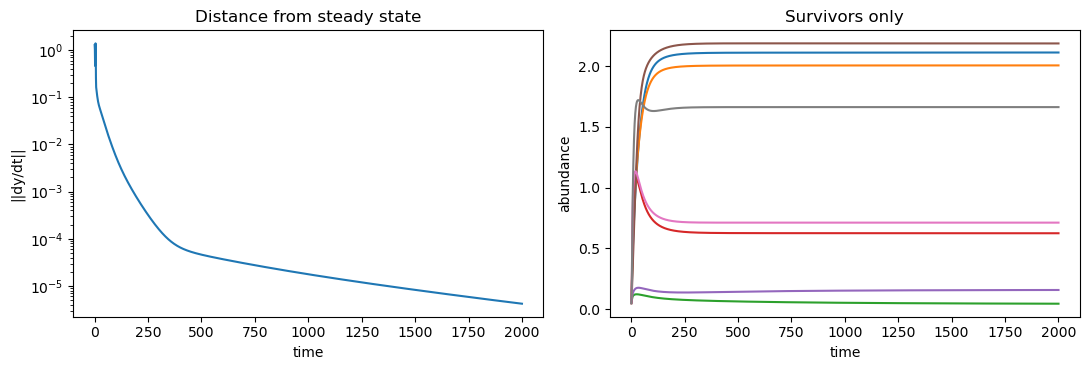

Approaches stable endpoint: True


In [9]:
print(f"min abundance over run : {N.min():.3e}")
print(f"min resource over run  : {R.min():.3e}")
print("nonnegative (tol 1e-8) :", bool(N.min() > -1e-8 and R.min() > -1e-8))

dN = species_derivatives(final, R[-1], p)
dR = resource_derivatives(final, R[-1], p)
print(f"max |dN/dt| at end: {np.abs(dN).max():.2e}   max |dR/dt| at end: {np.abs(dR).max():.2e}")

# Relative change in the community over a late window
tail = t >= 0.9 * t[-1]
change = np.abs(N[tail][-1] - N[tail][0]).max()
print(f"max abundance change over last 10% of run: {change:.2e}")

# Rate of change of total biomass and Shannon index over time
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
speed = np.linalg.norm(np.gradient(np.hstack([N, R]), t, axis=0), axis=1)
axes[0].semilogy(t, speed + 1e-16); axes[0].set(xlabel="time", ylabel="||dy/dt||", title="Distance from steady state")
axes[1].plot(t, N[:, final > THRESH]); axes[1].set(xlabel="time", ylabel="abundance", title="Survivors only")
plt.tight_layout(); plt.show()

stable = np.abs(dN).max() < 1e-3 and np.abs(dR).max() < 1e-3
print("Approaches stable endpoint:", stable)

# Shannon

Shannon H : start=3.219  max=3.219 (t=0)  final=1.772
Richness  : start=25  final=8
Evenness J: final=0.852


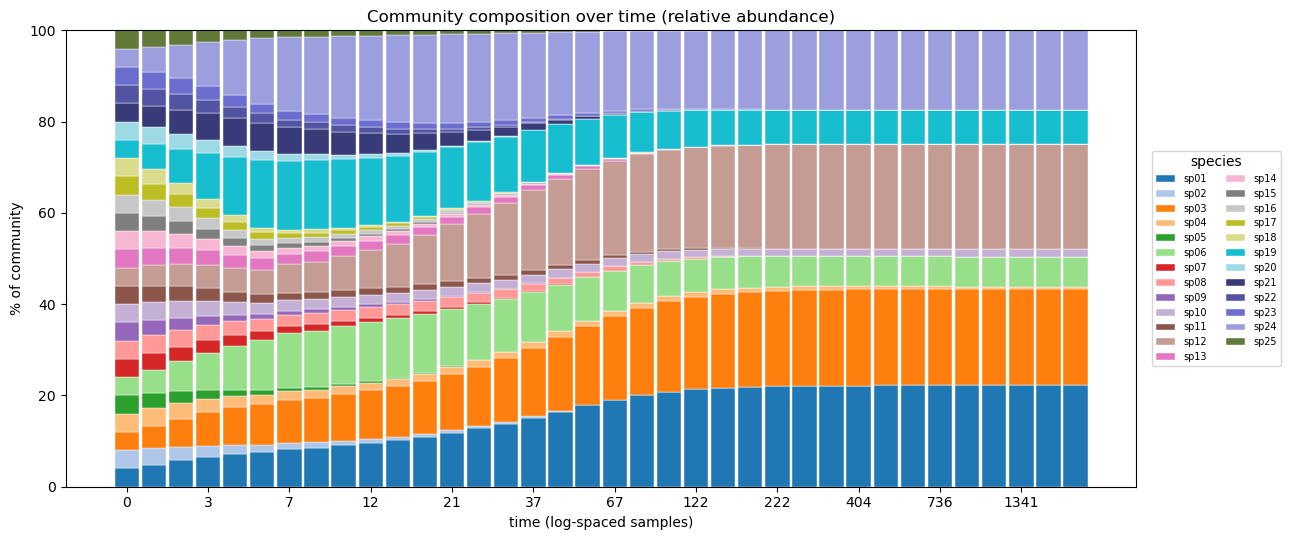

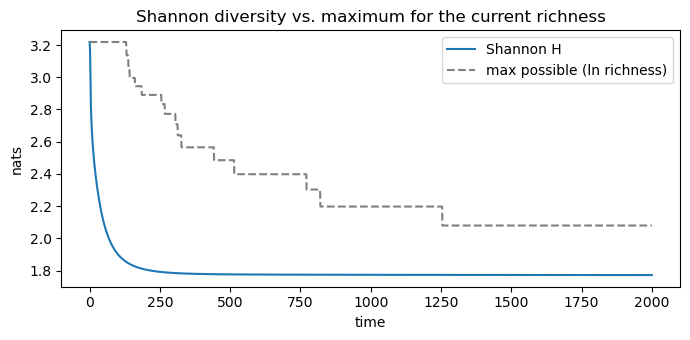

In [10]:
# ---- Shannon diversity + relative-abundance bar chart over time ----
# Uses t, N, p, THRESH from the earlier cells (time points, abundances (T x S),
# community params, extinction threshold).
import numpy as np
import matplotlib.pyplot as plt

# 1) Shannon diversity at every time point (species below THRESH are ignored)
Nc = np.where(N > THRESH, N, 0.0)
total = Nc.sum(axis=1, keepdims=True)
rel = np.divide(Nc, total, out=np.zeros_like(Nc), where=total > 0)      # relative abundances (T x S)
with np.errstate(divide="ignore", invalid="ignore"):
    H = -np.nansum(np.where(rel > 0, rel * np.log(rel), 0.0), axis=1)    # Shannon index (nats)
rich = (Nc > 0).sum(axis=1)
evenness = np.divide(H, np.log(rich), out=np.zeros_like(H), where=rich > 1)  # Pielou's J

print(f"Shannon H : start={H[0]:.3f}  max={H.max():.3f} (t={t[H.argmax()]:.0f})  final={H[-1]:.3f}")
print(f"Richness  : start={rich[0]}  final={rich[-1]}")
print(f"Evenness J: final={evenness[-1]:.3f}")

# 2) Stacked bar chart: % of community made up by each species over time
N_BARS = 40
SPACING = "log"          # "log" shows the fast early dynamics; "linear" gives evenly spaced times
if SPACING == "log":
    targets = np.geomspace(max(t[1], 1e-3), t[-1], N_BARS - 1)
    idx = np.unique(np.r_[0, np.searchsorted(t, targets)])
else:
    idx = np.unique(np.linspace(0, len(t) - 1, N_BARS).astype(int))
idx = idx[idx < len(t)]

pct = rel[idx] * 100                                               # (bars x S)
colors = list(plt.cm.tab20.colors) + list(plt.cm.tab20b.colors)    # 40 distinct colors
x = np.arange(len(idx))

fig, ax = plt.subplots(figsize=(13, 5.5))
bottom = np.zeros(len(idx))
for i in range(p.n_species):
    ax.bar(x, pct[:, i], bottom=bottom, width=0.9, color=colors[i % len(colors)],
           label=p.species_names[i], edgecolor="white", linewidth=0.3)
    bottom += pct[:, i]

step = max(1, len(idx) // 12)
ax.set_xticks(x[::step])
ax.set_xticklabels([f"{t[k]:.0f}" for k in idx[::step]])
ax.set(xlabel=f"time ({SPACING}-spaced samples)", ylabel="% of community", ylim=(0, 100),
       title="Community composition over time (relative abundance)")
ax.legend(ncol=2, fontsize=7, loc="center left", bbox_to_anchor=(1.01, 0.5), title="species")
plt.tight_layout(); plt.show()

# 3) Shannon index over time alongside the composition shift
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(t, H, label="Shannon H")
ax.plot(t, np.log(np.maximum(rich, 1)), "--", color="gray", label="max possible (ln richness)")
ax.set(xlabel="time", ylabel="nats", title="Shannon diversity vs. maximum for the current richness")
ax.legend(); plt.tight_layout(); plt.show()

# Survivor Statistics

## Survivor trait table: variable guide

Time and biomass units are arbitrary. "Final" means the last time point of the run (t = 2000 by default). A species counts as a **survivor** if its final abundance is above the extinction threshold (`THRESH` = 1e-6).

### Outcome columns

| Variable | Meaning |
|---|---|
| `species` | Species ID (sp01 to sp25). |
| `survived` | `True` if final abundance > `THRESH`, otherwise `False` (extinct). |
| `final_abundance` | Biomass of the species at the end of the simulation. |

### Species traits (inputs to the model)

| Variable | Meaning |
|---|---|
| `mu_max` | Maximum growth rate (1/time), reached when all resources are saturating. Higher is faster growth. |
| `mortality` | Density-independent loss rate (1/time). Lower is better. |
| `leakage` | Fraction of the species' resource uptake that is released back into the environment as byproduct metabolites (fuel for cross-feeding). It reduces how much goes to biomass. |
| `initial_abundance` | Starting biomass at t = 0. |
| `main_resource` | The resource the species prefers most (the one with the largest preference value): R1, R2 or R3. |
| `specialization` | The largest preference value for that species. 1 means a pure specialist on one resource; 1/3 means an even generalist across the 3 resources. |
| `pref_R1`, `pref_R2`, `pref_R3` | Resource-use preference for each resource (matrix `U`). Each species' three values sum to 1. |
| `mean_K_weighted` | Preference-weighted average half-saturation constant (`K`). Lower means the species grows better at low resource concentrations (a better scavenger). |
| `mean_yield_weighted` | Preference-weighted average biomass yield (`e`): biomass produced per unit of resource consumed. Higher is more efficient. |
| `susceptibility (unused)` | Future antibiotic trait in [0, 1] (0 = strongly resistant, 1 = highly susceptible). It is **not used** by the baseline dynamics and is shown only for reference. |

### Derived fitness columns

| Variable | Meaning |
|---|---|
| `invasion_growth` | Net growth rate of a rare invader at the final resource concentrations: resource-driven growth minus `mortality`. Positive means the species can persist in that environment; zero or negative means it cannot. It is largely a consequence of the survivors having set the final resource levels, so it explains why, rather than predicts which. |
| `growth_vs_mortality` | Resource-driven growth divided by `mortality` at the final resource concentrations. Values above 1 mean growth exceeds losses (the same criterion as `invasion_growth` > 0, on a ratio scale). |

### Survivor vs extinct comparison table

| Variable | Meaning |
|---|---|
| `trait` | The trait being compared. |
| `survivor_mean` | Average value of that trait among survivors. |
| `extinct_mean` | Average value of that trait among extinct species. |
| `p_value` | Mann-Whitney U test p-value for a difference between the two groups. With few survivors, treat it as descriptive, not as proof (and it comes from a single seed). |

Survivors: 8 / 25


,species,final_abundance,mu_max,mortality,leakage,initial_abundance,main_resource,specialization,mean_K_weighted,mean_yield_weighted,susceptibility (unused),pref_R1,pref_R2,pref_R3,invasion_growth,growth_vs_mortality
0,sp12,2.186,0.956,0.063,0.287,0.05,R3,0.881,0.261,0.414,0.979,0.091,0.028,0.881,0.044,1.694
1,sp01,2.112,0.864,0.069,0.253,0.05,R1,0.508,0.422,0.475,0.477,0.508,0.357,0.135,0.042,1.608
2,sp03,2.005,0.915,0.054,0.173,0.05,R1,0.571,0.596,0.292,0.865,0.571,0.426,0.003,0.040,1.738
3,sp24,1.662,0.936,0.118,0.237,0.05,R1,0.752,0.440,0.380,0.500,0.752,0.247,0.001,0.033,1.281
4,sp19,0.712,0.897,0.081,0.124,0.05,R1,0.822,0.550,0.245,0.526,0.822,0.095,0.082,0.014,1.175
5,sp06,0.625,0.985,0.124,0.130,0.05,R1,0.600,0.398,0.314,0.284,0.600,0.001,0.399,0.012,1.100
6,sp10,0.158,0.670,0.097,0.246,0.05,R2,0.631,0.273,0.388,0.717,0.047,0.631,0.322,0.003,1.033
7,sp04,0.045,0.818,0.065,0.163,0.05,R2,0.944,0.488,0.345,0.285,0.050,0.944,0.006,0.001,1.013


,trait,survivor_mean,extinct_mean,p_value
0,mu_max,0.8803,0.7116,0.0074
1,mortality,0.0841,0.1018,0.1104
2,leakage,0.2015,0.2087,0.7108
3,initial_abundance,0.0500,0.0500,1.0000
4,specialization,0.7138,0.7447,0.7108
5,mean_K_weighted,0.4285,0.5934,0.0975
6,mean_yield_weighted,0.3566,0.3681,0.7538
7,invasion_growth,0.0238,-0.0507,0.0000
8,pref_R1,0.4303,0.1230,0.0427
9,pref_R2,0.3411,0.4127,0.5110


Survivors by main resource:


survived,False,True
main_resource,,
R1,1,5
R2,8,2
R3,8,1


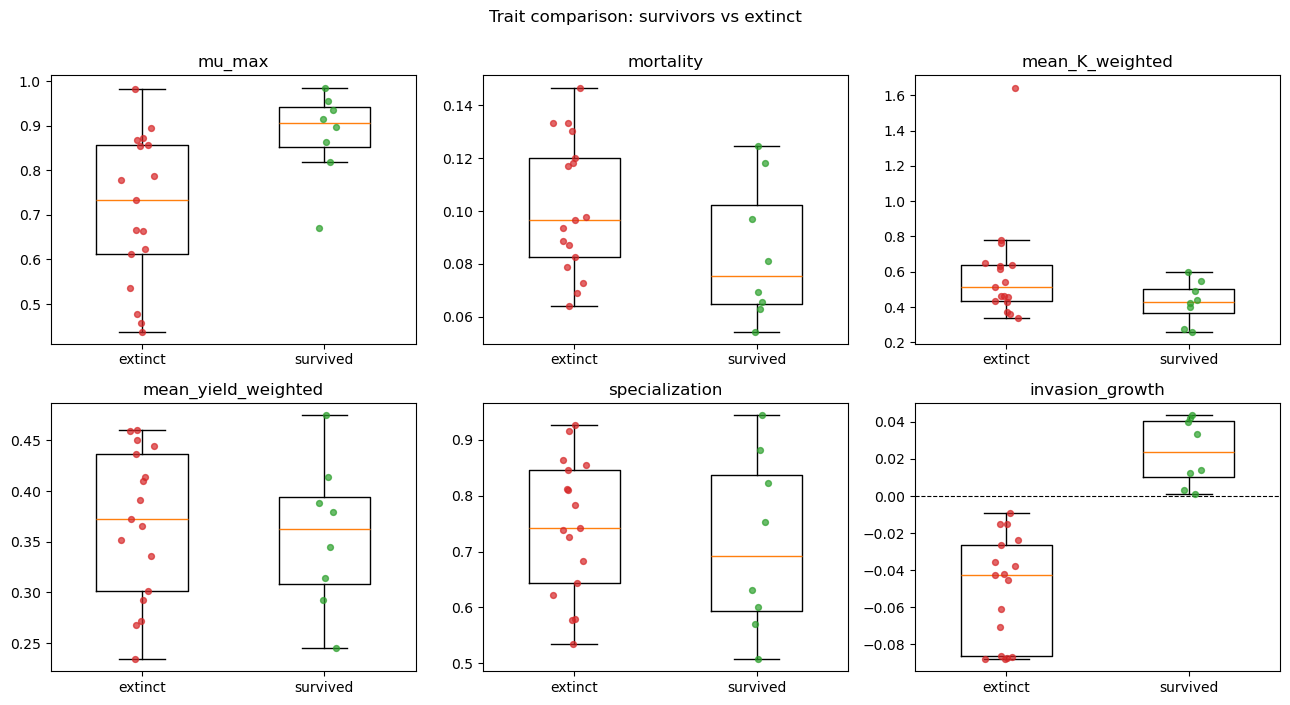

In [11]:
# ---- Which traits led to survival? ----
# Uses t, N, R, p, THRESH, community from earlier cells.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu
from consumer_resource_model import growth_rates

final_N, final_R = N[-1], R[-1]
survived = final_N > THRESH

# Trait table (one row per species)
df = pd.DataFrame({
    "species": p.species_names,
    "survived": survived,
    "final_abundance": final_N,
    "mu_max": p.mu_max,
    "mortality": p.mortality,
    "leakage": p.leakage,
    "initial_abundance": p.initial_abundance,
    "main_resource": [p.resource_names[k] for k in p.preference.argmax(axis=1)],
    "specialization": p.preference.max(axis=1),                 # 1 = pure specialist, 1/3 = generalist
    "mean_K_weighted": (p.preference * p.half_saturation).sum(axis=1),   # preference-weighted half-saturation
    "mean_yield_weighted": (p.preference * p.efficiency).sum(axis=1),
    "susceptibility (unused)": community.future.susceptibility,
})
for j, name in enumerate(p.resource_names):
    df[f"pref_{name}"] = p.preference[:, j]

# Mechanistic fitness: net growth of a rare invader at the final resource levels.
# Positive = species can persist in this environment; <= 0 = it cannot.
df["invasion_growth"] = growth_rates(final_R, p) - p.mortality
df["growth_vs_mortality"] = growth_rates(final_R, p) / p.mortality

print(f"Survivors: {survived.sum()} / {len(df)}")
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30)
display(df[df.survived].sort_values("final_abundance", ascending=False)
        .drop(columns="survived").round(3).reset_index(drop=True))

# Survivor vs extinct comparison (means + Mann-Whitney p-value)
traits = ["mu_max", "mortality", "leakage", "initial_abundance", "specialization",
          "mean_K_weighted", "mean_yield_weighted", "invasion_growth",
          "pref_R1", "pref_R2", "pref_R3", "susceptibility (unused)"]
rows = []
for tr in traits:
    a, b = df.loc[df.survived, tr], df.loc[~df.survived, tr]
    pv = mannwhitneyu(a, b).pvalue if len(a) > 1 and len(b) > 1 else np.nan
    rows.append({"trait": tr, "survivor_mean": a.mean(), "extinct_mean": b.mean(), "p_value": pv})
cmp_df = pd.DataFrame(rows)
display(cmp_df.round(4))
print("Survivors by main resource:")
display(pd.crosstab(df.main_resource, df.survived))

# Plots: trait distributions, survivors vs extinct
plot_traits = ["mu_max", "mortality", "mean_K_weighted", "mean_yield_weighted",
               "specialization", "invasion_growth"]
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, tr in zip(axes.ravel(), plot_traits):
    groups = [df.loc[~df.survived, tr], df.loc[df.survived, tr]]
    ax.boxplot(groups, widths=0.5, showfliers=False)
    ax.set_xticks([1, 2]); ax.set_xticklabels(["extinct", "survived"])
    for k, g in enumerate(groups):
        ax.scatter(np.random.default_rng(0).normal(k + 1, 0.05, len(g)), g, s=18, alpha=0.7,
                   color=["tab:red", "tab:green"][k], zorder=3)
    ax.set_title(tr)
    if tr == "invasion_growth":
        ax.axhline(0, color="k", lw=0.8, ls="--")
plt.suptitle("Trait comparison: survivors vs extinct", y=1.0); plt.tight_layout(); plt.show()

# Does invasion growth rate explain who survives